# OASIS-1 Exploratory Data Analysis

Covers two parts:
1. **Demographic / clinical CSV** — distributions, missingness, CDR/MMSE relationships, group tests
2. **Neuroimaging (.nii)** — file inventory, header metadata, intensity stats, slice visualisation, group-mean images

**Set the paths in the Config cell first.** Install deps if needed: `pip install nibabel pandas numpy matplotlib seaborn scipy tqdm`

## 1. Config & imports

In [5]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# ----------------------------- EDIT THESE -----------------------------
CSV_PATH = Path("/kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis_cross-sectional.csv")   # demographics CSV
NII_DIR  = Path("/kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis/OASIS")                # root folder containing .nii / .nii.gz files
ID_REGEX = r"(OAS1_\d{4}_MR\d)"              # pattern to pull the session ID out of a filename
MAX_SCANS_FOR_STATS = None                     # e.g. 100 for a quick run; None = all
RANDOM_STATE = 42
# ----------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)

## 2. Shared helpers

Pip deps for this notebook: `pip install nibabel pandas numpy matplotlib seaborn scipy scikit-learn plotly ipywidgets tqdm`

In [6]:
# Shared imports + helpers used by many later cells (run once, near the top)
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import ndimage
from scipy.ndimage import zoom
import ipywidgets as W
from IPython.display import display as ipd

def load_vol(path):
    """Load a NIfTI as float32 and drop singleton dims (OASIS-1 often has a trailing 1)."""
    vol = np.asarray(nib.load(str(path)).dataobj, dtype=np.float32)
    return np.squeeze(vol)

def mid_slice(v, frac=0.5):
    return v[:, :, int(v.shape[2] * frac)]

def norm01(s):
    lo, hi = np.percentile(s, 1), np.percentile(s, 99)
    return np.clip((s - lo) / (hi - lo + 1e-8), 0, 1)

def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826 + 1e-12
    return (s - med) / mad

order = ["Nondemented", "Very mild", "Mild", "Moderate"]   # CDR 0 / 0.5 / 1 / 2

## 3. Load demographics CSV

In [7]:
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
print(df.shape)
df.head()

(436, 12)


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,0.0,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,0.0,1737,0.848,1.010,NaN


In [8]:
# Standard OASIS-1 columns: ID, M/F, Hand, Age, Educ, SES, MMSE, CDR, eTIV, nWBV, ASF, Delay
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 436 entries, 0 to 435
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      436 non-null    object 
 1   M/F     436 non-null    object 
 2   Hand    436 non-null    object 
 3   Age     436 non-null    int64  
 4   Educ    235 non-null    float64
 5   SES     216 non-null    float64
 6   MMSE    235 non-null    float64
 7   CDR     436 non-null    float64
 8   eTIV    436 non-null    int64  
 9   nWBV    436 non-null    float64
 10  ASF     436 non-null    float64
 11  Delay   20 non-null     float64
dtypes: float64(7), int64(2), object(3)
memory usage: 41.0+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,436,436,OAS1_0395_MR2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M/F,436,2,F,268,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hand,436,1,R,436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,436.0,NaN,NaN,NaN,51.357798,25.269862,18.0,23.0,54.0,74.0,96.0
Educ,235.0,NaN,NaN,NaN,3.178723,1.31151,1.0,2.0,3.0,4.0,5.0
SES,216.0,NaN,NaN,NaN,2.490741,1.120593,1.0,2.0,2.0,3.0,5.0
MMSE,235.0,NaN,NaN,NaN,27.06383,3.69687,14.0,26.0,29.0,30.0,30.0
CDR,436.0,NaN,NaN,NaN,0.15367,0.31515,0.0,0.0,0.0,0.0,2.0
eTIV,436.0,NaN,NaN,NaN,1481.919725,158.740866,1123.0,1367.75,1475.5,1579.25,1992.0
nWBV,436.0,NaN,NaN,NaN,0.79167,0.059937,0.644,0.74275,0.809,0.842,0.893


### Column reference
| Column | Meaning |
|---|---|
| ID | Session ID (e.g. `OAS1_0001_MR1`) |
| M/F | Sex |
| Hand | Handedness (all right-handed in OASIS-1) |
| Age | Age at scan |
| Educ | Education code 1–5 |
| SES | Socioeconomic status 1–5 (1 = highest) |
| MMSE | Mini-Mental State Examination (0–30) |
| CDR | Clinical Dementia Rating (0, 0.5, 1, 2) |
| eTIV | Estimated total intracranial volume (mm³) |
| nWBV | Normalised whole-brain volume |
| ASF | Atlas scaling factor |
| Delay | Days between MR and clinical assessment (reliability check subjects) |

## 4. Data quality: missingness & duplicates

,missing,pct
Delay,416,95.4
SES,220,50.5
Educ,201,46.1
MMSE,201,46.1


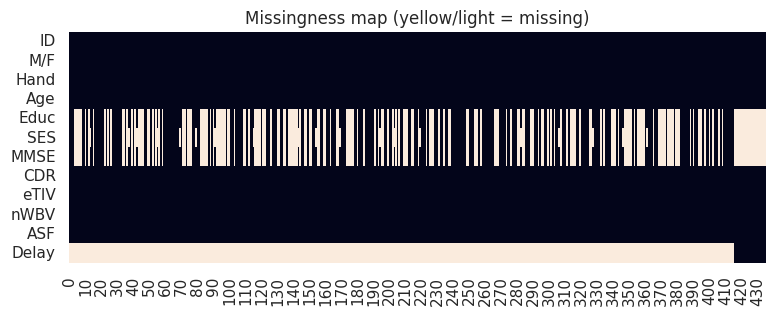

Duplicate IDs: 0


In [9]:
miss = df.isna().sum().to_frame("missing")
miss["pct"] = (miss["missing"] / len(df) * 100).round(1)
display(miss[miss.missing > 0].sort_values("missing", ascending=False))

fig, ax = plt.subplots(figsize=(9, 3))
sns.heatmap(df.isna().T, cbar=False, ax=ax, yticklabels=True)
ax.set_title("Missingness map (yellow/light = missing)")
plt.show()

print("Duplicate IDs:", df["ID"].duplicated().sum())

In [10]:
# Subject-level vs session-level: OASIS-1 has repeat scans (MR2) for some subjects
df["subject"] = df["ID"].str.extract(r"(OAS1_\d{4})")
df["session"] = df["ID"].str.extract(r"_(MR\d)")
print("Sessions:", len(df), "| Unique subjects:", df.subject.nunique())
print(df.session.value_counts())

Sessions: 436 | Unique subjects: 416
session
MR1    416
MR2     20
Name: count, dtype: int64


**Note:** Clinical variables (MMSE, CDR, SES, Educ) are only available for subjects aged 60+. Younger subjects (18–59) typically have NaN there, so missingness is **structural, not random**.

In [11]:
df["age_group"] = pd.cut(df["Age"], bins=[0, 29, 39, 49, 59, 69, 79, 120],
                         labels=["<30", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"])
print(df.groupby("age_group")[["MMSE", "CDR", "SES", "Educ"]].apply(lambda g: g.isna().mean().round(2)))

           MMSE  CDR   SES  Educ
age_group                       
<30        1.00  0.0  1.00  1.00
30-39      0.88  0.0  0.88  0.88
40-49      0.58  0.0  0.61  0.58
50-59      0.33  0.0  0.33  0.33
60-69      0.00  0.0  0.15  0.00
70-79      0.00  0.0  0.11  0.00
80+        0.00  0.0  0.04  0.00


## 5. Demographic distributions

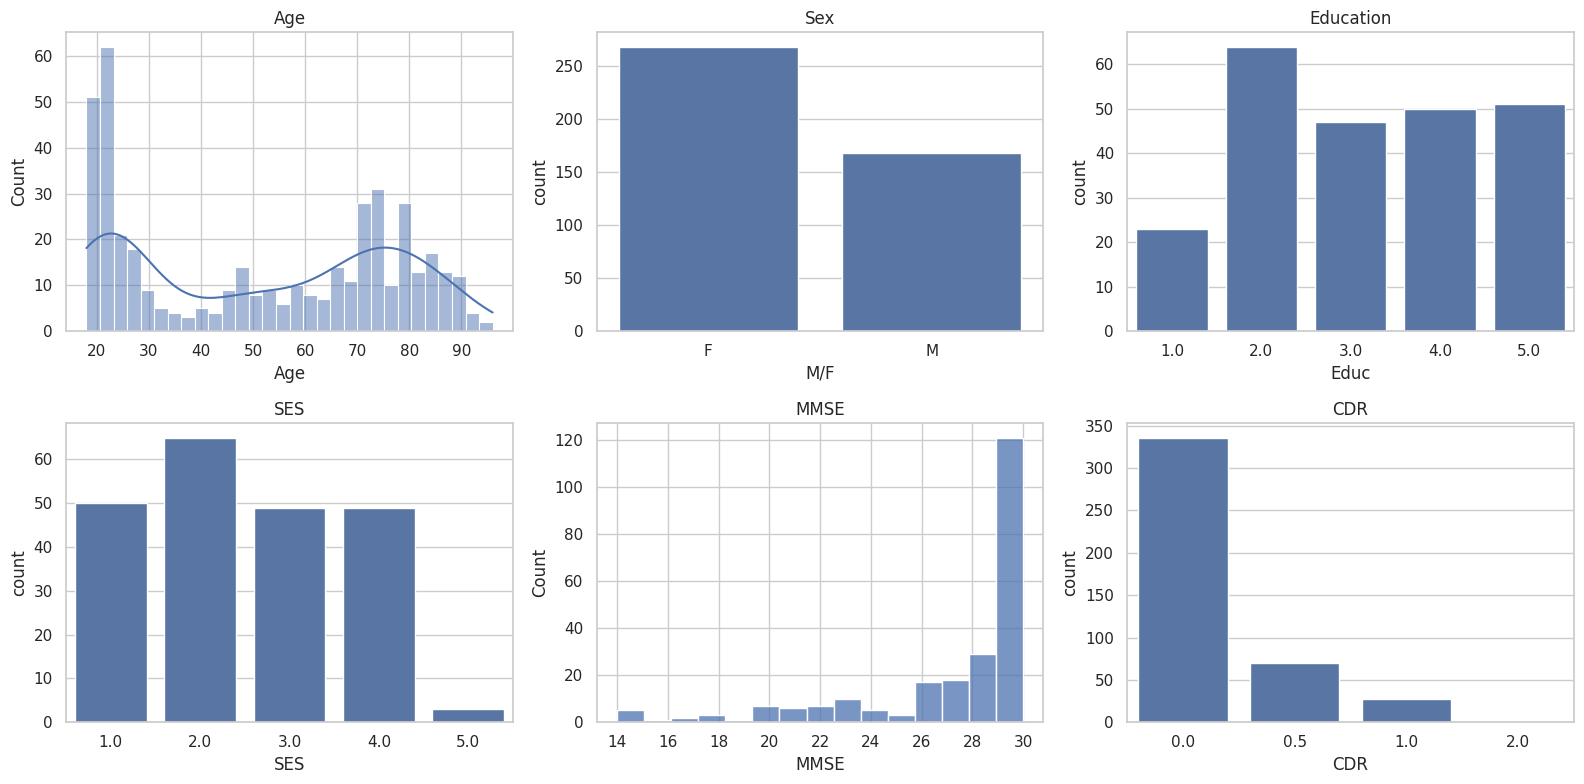

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df["Age"], bins=30, kde=True, ax=axes[0, 0]); axes[0, 0].set_title("Age")
sns.countplot(x="M/F", data=df, ax=axes[0, 1]); axes[0, 1].set_title("Sex")
sns.countplot(x="Educ", data=df, ax=axes[0, 2]); axes[0, 2].set_title("Education")
sns.countplot(x="SES", data=df, ax=axes[1, 0]); axes[1, 0].set_title("SES")
sns.histplot(df["MMSE"].dropna(), bins=15, ax=axes[1, 1]); axes[1, 1].set_title("MMSE")
sns.countplot(x="CDR", data=df, ax=axes[1, 2]); axes[1, 2].set_title("CDR")
plt.tight_layout(); plt.show()

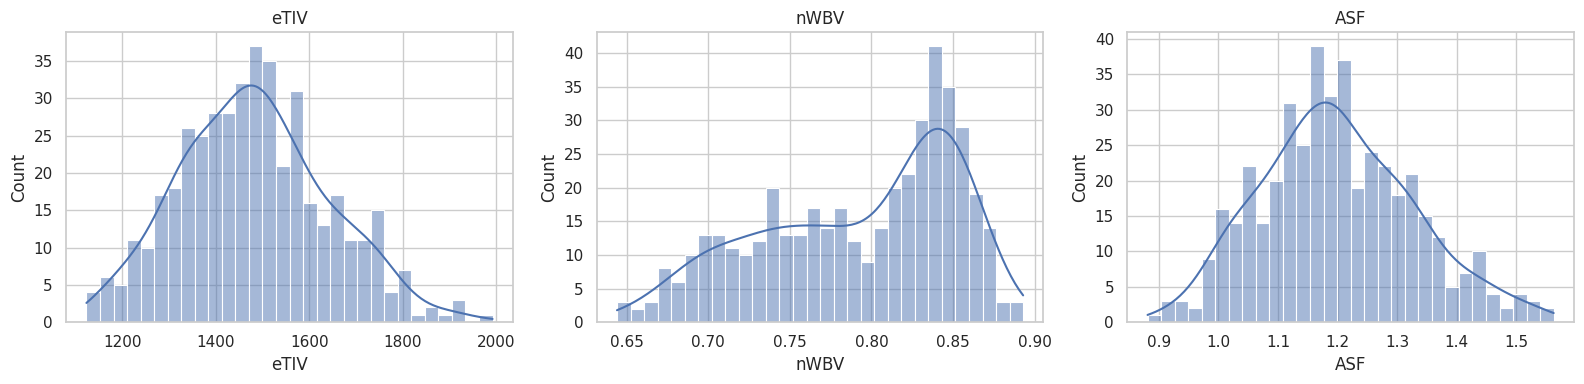

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["eTIV", "nWBV", "ASF"]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

## 6. Class balance (CDR)

,count,pct
CDR,,
0.0,336,77.1
0.5,70,16.1
1.0,28,6.4
2.0,2,0.5


label_binary
Nondemented    336
Demented       100
Name: count, dtype: int64


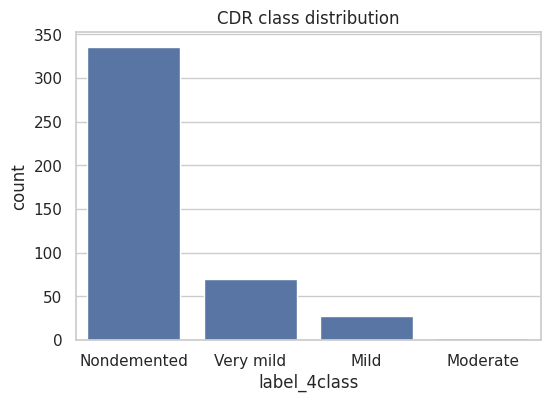

In [14]:
cdr_counts = df["CDR"].value_counts(dropna=False).sort_index()
cdr_pct = (cdr_counts / cdr_counts.sum() * 100).round(1)
display(pd.DataFrame({"count": cdr_counts, "pct": cdr_pct}))

# Common label schemes
df["label_4class"] = df["CDR"].map({0.0: "Nondemented", 0.5: "Very mild", 1.0: "Mild", 2.0: "Moderate"})
df["label_binary"] = df["CDR"].map(lambda x: np.nan if pd.isna(x) else ("Demented" if x > 0 else "Nondemented"))
print(df["label_binary"].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="label_4class", data=df, order=["Nondemented", "Very mild", "Mild", "Moderate"], ax=ax)
ax.set_title("CDR class distribution"); plt.show()

## 7. Clinical variables vs CDR

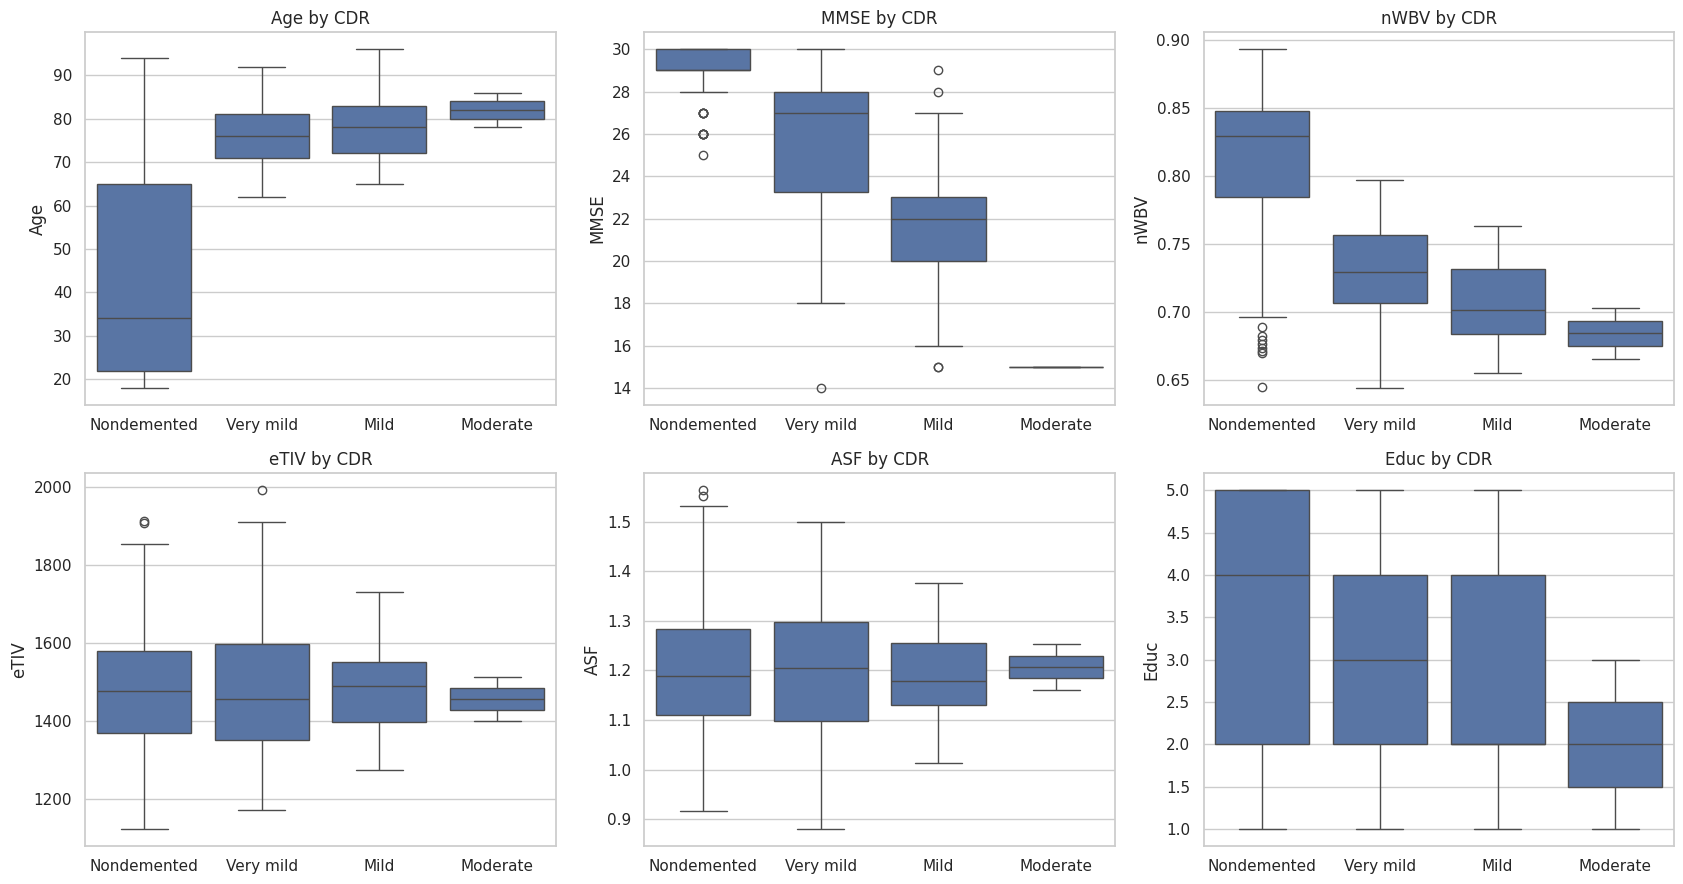

In [15]:
labeled = df.dropna(subset=["CDR"]).copy()
order = ["Nondemented", "Very mild", "Mild", "Moderate"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), ["Age", "MMSE", "nWBV", "eTIV", "ASF", "Educ"]):
    sns.boxplot(x="label_4class", y=col, data=labeled, order=order, ax=ax)
    ax.set_xlabel("")
    ax.set_title(f"{col} by CDR")
plt.tight_layout(); plt.show()

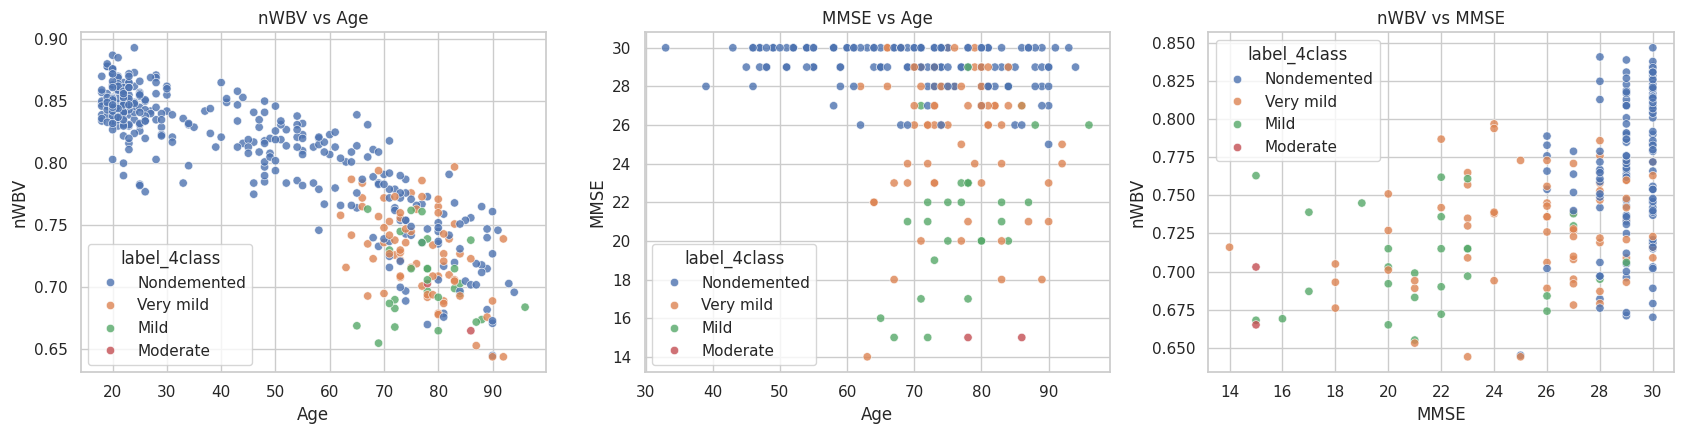

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=labeled, x="Age", y="nWBV", hue="label_4class", hue_order=order, ax=axes[0], alpha=.8)
axes[0].set_title("nWBV vs Age")
sns.scatterplot(data=labeled, x="Age", y="MMSE", hue="label_4class", hue_order=order, ax=axes[1], alpha=.8)
axes[1].set_title("MMSE vs Age")
sns.scatterplot(data=labeled, x="MMSE", y="nWBV", hue="label_4class", hue_order=order, ax=axes[2], alpha=.8)
axes[2].set_title("nWBV vs MMSE")
plt.tight_layout(); plt.show()

label_4class,Nondemented,Very mild,Mild,Moderate
M/F,,,,
F,209,39,19,1
M,127,31,9,1


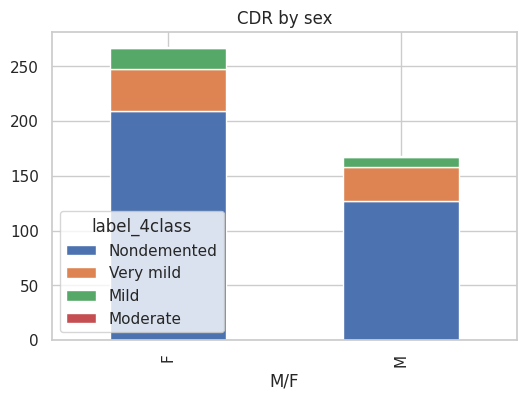

In [17]:
# Sex x CDR
ct = pd.crosstab(labeled["M/F"], labeled["label_4class"])
ct = ct[[o for o in order if o in ct.columns]]
display(ct)
ct.plot(kind="bar", stacked=True, figsize=(6, 4)); plt.title("CDR by sex"); plt.show()

## 8. Correlations

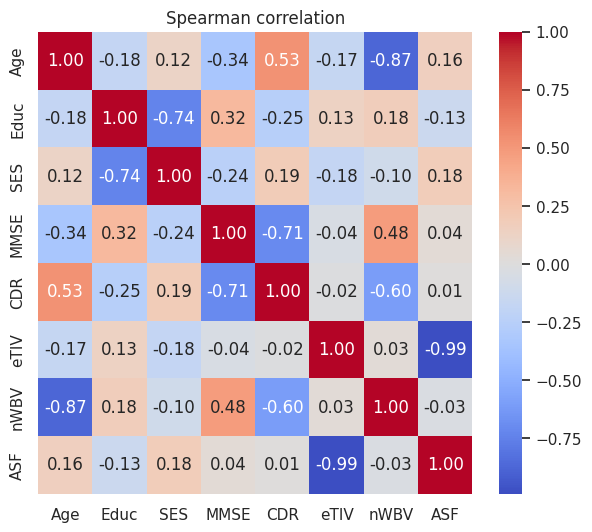

In [18]:
num_cols = ["Age", "Educ", "SES", "MMSE", "CDR", "eTIV", "nWBV", "ASF"]
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation"); plt.show()

`eTIV` and `ASF` are almost perfectly (inversely) related — they carry the same information, so avoid using both in a tabular model.

## 9. Statistical tests across CDR groups

In [19]:
rows = []
for col in ["Age", "MMSE", "nWBV", "eTIV", "Educ"]:
    groups = [g[col].dropna().values for _, g in labeled.groupby("label_4class") if g[col].notna().sum() > 1]
    if len(groups) > 1:
        H, p = stats.kruskal(*groups)
        rows.append({"variable": col, "Kruskal-Wallis H": round(H, 2), "p-value": p})
display(pd.DataFrame(rows))

# Chi-square: sex vs binary label
tab = pd.crosstab(labeled["M/F"], labeled["label_binary"])
chi2, p, dof, _ = stats.chi2_contingency(tab)
print(f"Sex vs Demented: chi2={chi2:.2f}, dof={dof}, p={p:.4f}")

,variable,Kruskal-Wallis H,p-value
0,Age,122.37,2.385593e-26
1,MMSE,117.68,2.437101e-25
2,nWBV,159.19,2.734449e-34
3,eTIV,0.20,9.770714e-01
4,Educ,15.38,1.515698e-03


Sex vs Demented: chi2=0.21, dof=1, p=0.6451


## 10. Link NIfTI files to the CSV

In [20]:
nii_files = sorted(list(NII_DIR.rglob("*.nii")) + list(NII_DIR.rglob("*.nii.gz")))
print("NIfTI files found:", len(nii_files))
for f in nii_files[:5]:
    print(" ", f)

def extract_id(p):
    m = re.search(ID_REGEX, str(p))
    return m.group(1) if m else None

files = pd.DataFrame({"path": nii_files})
files["ID"] = files["path"].map(extract_id)
files["fname"] = files["path"].map(lambda p: p.name)
print("Files with no parsable ID:", files["ID"].isna().sum())
files.head()

NIfTI files found: 436
  /kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis/OASIS/OAS1_0001_MR1_mpr_n4_anon_sbj_111_normalised.nii
  /kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis/OASIS/OAS1_0002_MR1_mpr_n4_anon_sbj_111_normalised.nii
  /kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis/OASIS/OAS1_0003_MR1_mpr_n4_anon_sbj_111_normalised.nii
  /kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis/OASIS/OAS1_0004_MR1_mpr_n4_anon_sbj_111_normalised.nii
  /kaggle/input/datasets/ninadaithal/oasis-1-shinohara/oasis/OASIS/OAS1_0005_MR1_mpr_n4_anon_sbj_111_normalised.nii
Files with no parsable ID: 0


,path,ID,fname
0,/kaggle/input/datasets/ninadaithal/oasis-1-shi...,OAS1_0001_MR1,OAS1_0001_MR1_mpr_n4_anon_sbj_111_normalised.nii
1,/kaggle/input/datasets/ninadaithal/oasis-1-shi...,OAS1_0002_MR1,OAS1_0002_MR1_mpr_n4_anon_sbj_111_normalised.nii
2,/kaggle/input/datasets/ninadaithal/oasis-1-shi...,OAS1_0003_MR1,OAS1_0003_MR1_mpr_n4_anon_sbj_111_normalised.nii
3,/kaggle/input/datasets/ninadaithal/oasis-1-shi...,OAS1_0004_MR1,OAS1_0004_MR1_mpr_n4_anon_sbj_111_normalised.nii
4,/kaggle/input/datasets/ninadaithal/oasis-1-shi...,OAS1_0005_MR1,OAS1_0005_MR1_mpr_n4_anon_sbj_111_normalised.nii


In [21]:
# Multiple files per session are common (raw scans, averages, masked, atlas-registered, segmented...)
print("Files per session:"); print(files.groupby("ID").size().describe())

# Show filename patterns to decide which image variant to use
files["variant"] = files["fname"].str.replace(ID_REGEX, "<ID>", regex=True).str.replace(r"\d+", "#", regex=True)
display(files["variant"].value_counts().head(15))

Files per session:
count    436.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64


variant
<ID>_mpr_n#_anon_sbj_#_normalised.nii            434
<ID>_mpr_n#_fdcanon_sbj_#.#dfp_normalised.nii      2
Name: count, dtype: int64

In [22]:
# --- Choose ONE variant for analysis (edit after inspecting the table above) ---
VARIANT_FILTER = None   # e.g. "masked_gfc" or "t88" -> keeps filenames containing that substring
sel = files.copy()
if VARIANT_FILTER:
    sel = sel[sel["fname"].str.contains(VARIANT_FILTER)]
sel = sel.dropna(subset=["ID"]).drop_duplicates("ID").reset_index(drop=True)

merged = sel.merge(df, on="ID", how="outer", indicator=True)
print(merged["_merge"].value_counts())
print("CSV rows without image:", (merged["_merge"] == "right_only").sum())
print("Images without CSV row:", (merged["_merge"] == "left_only").sum())

data = merged[merged["_merge"] == "both"].drop(columns="_merge").reset_index(drop=True)
print("Usable image+CSV pairs:", len(data))

_merge
both          436
left_only       0
right_only      0
Name: count, dtype: int64
CSV rows without image: 0
Images without CSV row: 0
Usable image+CSV pairs: 436


## 11. Dataset summary table

In [23]:
n_f = int((df["M/F"] == "F").sum()); n_m = int((df["M/F"] == "M").sum())
summary = pd.DataFrame({
    "Metric": [
        "Sessions (CSV rows)", "Unique subjects", "NIfTI files found", "Usable image+CSV pairs",
        "Labelled sessions (CDR present)", "Number of classes (CDR)", "Age range (mean)",
        "Sex F / M", "Missing cells in CSV (%)", "Subjects with >1 session",
    ],
    "Value": [
        len(df), df["subject"].nunique(), len(files), len(data),
        int(df["CDR"].notna().sum()), df["CDR"].nunique(),
        f"{df.Age.min():.0f}–{df.Age.max():.0f} ({df.Age.mean():.1f})",
        f"{n_f} / {n_m}", f"{df.isna().mean().mean()*100:.1f}",
        int((df.groupby('subject').size() > 1).sum()),
    ],
})
display(summary.style.hide(axis="index"))

Metric,Value
Sessions (CSV rows),436
Unique subjects,416
NIfTI files found,436
Usable image+CSV pairs,436
Labelled sessions (CDR present),436
Number of classes (CDR),4
Age range (mean),18–96 (51.4)
Sex F / M,268 / 168
Missing cells in CSV (%),14.0
Subjects with >1 session,20


## 12. Class balance in the usable image set (counts, ratio, class weights)

In [24]:
counts = data["label_4class"].value_counts().reindex(order).dropna().astype(int)
pct = (counts / counts.sum() * 100).round(1)
ratio = counts.max() / counts.min()

bal = pd.DataFrame({"count": counts, "percent": pct})
bal["ratio_to_majority"] = (counts.max() / counts).round(2)
bal["class_weight"] = (counts.sum() / (len(counts) * counts)).round(3)   # for CrossEntropyLoss(weight=...)
display(bal)

print(f"Majority: {counts.idxmax()} ({counts.max()}) | Minority: {counts.idxmin()} ({counts.min()})")
print(f"Majority-to-minority ratio = {ratio:.1f} : 1")
print("Severity:", "balanced" if ratio < 1.5 else "moderate imbalance" if ratio < 4 else "severe imbalance")

fig = px.bar(bal.reset_index(names="class"), x="class", y="count", text="count",
             hover_data=["percent", "ratio_to_majority", "class_weight"],
             title=f"Class balance (imbalance ratio {ratio:.1f}:1)", color="class")
fig.update_layout(showlegend=False); fig.show()

,count,percent,ratio_to_majority,class_weight
label_4class,,,,
Nondemented,336,77.1,1.0,0.324
Very mild,70,16.1,4.8,1.557
Mild,28,6.4,12.0,3.893
Moderate,2,0.5,168.0,54.500


Majority: Nondemented (336) | Minority: Moderate (2)
Majority-to-minority ratio = 168.0 : 1
Severity: severe imbalance


## 13. NIfTI header / geometry inventory

In [25]:
def header_info(path):
    img = nib.load(str(path))
    h = img.header
    zooms = h.get_zooms()[:3]
    return {
        "shape": tuple(img.shape),
        "ndim": img.ndim,
        "dtype": str(h.get_data_dtype()),
        "vx": zooms[0], "vy": zooms[1], "vz": zooms[2],
        "orientation": "".join(nib.aff2axcodes(img.affine)),
        "file_mb": Path(path).stat().st_size / 1e6,
    }

subset = data if MAX_SCANS_FOR_STATS is None else data.sample(min(MAX_SCANS_FOR_STATS, len(data)), random_state=RANDOM_STATE)
hdr = pd.DataFrame([header_info(p) for p in tqdm(subset["path"], desc="headers")], index=subset.index)
meta = subset.join(hdr)
for c in ["shape", "orientation", "dtype"]:
    print(f"\n{c}:"); print(meta[c].value_counts().head(10))
display(meta[["vx", "vy", "vz", "file_mb"]].describe())

headers:   0%|          | 0/436 [00:00<?, ?it/s]


shape:
shape
(91, 109, 91)    436
Name: count, dtype: int64

orientation:
orientation
LAS    436
Name: count, dtype: int64

dtype:
dtype
float32    436
Name: count, dtype: int64


,vx,vy,vz,file_mb
count,436.0,436.0,436.0,4.360000e+02
mean,2.0,2.0,2.0,3.610868e+00
std,0.0,0.0,0.0,1.422718e-14
min,2.0,2.0,2.0,3.610868e+00
25%,2.0,2.0,2.0,3.610868e+00
50%,2.0,2.0,2.0,3.610868e+00
75%,2.0,2.0,2.0,3.610868e+00
max,2.0,2.0,2.0,3.610868e+00


If shapes / voxel sizes / orientations are not uniform, you need to **resample or crop** before batching images for a model.

## 14. Image size / resolution

In [26]:
res = meta.copy()
res["shape_str"] = res["shape"].astype(str)
res["voxel_str"] = res[["vx", "vy", "vz"]].round(2).astype(str).agg(" x ".join, axis=1)
res["fov_mm"] = res.apply(lambda r: tuple(np.round(np.array(r["shape"][:3]) * np.array([r.vx, r.vy, r.vz]), 0)), axis=1)

display(res["shape_str"].value_counts().rename("n_scans").to_frame())
display(res["voxel_str"].value_counts().rename("n_scans").to_frame())
display(res["fov_mm"].astype(str).value_counts().rename("n_scans").to_frame())
print("Uniform shape:", res["shape_str"].nunique() == 1, "| Uniform voxel size:", res["voxel_str"].nunique() == 1)

fig = px.scatter(res, x="file_mb", y="vx", color="label_4class", hover_data=["ID", "shape_str", "voxel_str"],
                 title="File size vs voxel size (x), coloured by class")
fig.show()

# Is resolution confounded with the label?
display(pd.crosstab(res["label_4class"], res["shape_str"]))

,n_scans
shape_str,
"(91, 109, 91)",436


,n_scans
voxel_str,
2.0 x 2.0 x 2.0,436


,n_scans
fov_mm,
"(np.float64(182.0), np.float64(218.0), np.float64(182.0))",436


Uniform shape: True | Uniform voxel size: True


shape_str,"(91, 109, 91)"
label_4class,
Mild,28
Moderate,2
Nondemented,336
Very mild,70


## 15. Visualise scans

OAS1_0001_MR1 (91, 109, 91)


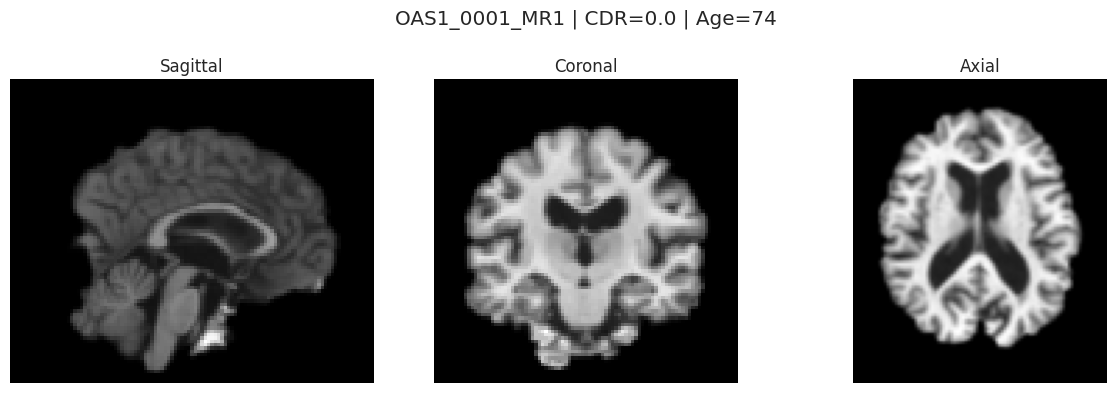

In [27]:
def show_three_planes(vol, title=""):
    x, y, z = [s // 2 for s in vol.shape[:3]]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(np.rot90(vol[x, :, :]), cmap="gray"); axes[0].set_title("Sagittal")
    axes[1].imshow(np.rot90(vol[:, y, :]), cmap="gray"); axes[1].set_title("Coronal")
    axes[2].imshow(np.rot90(vol[:, :, z]), cmap="gray"); axes[2].set_title("Axial")
    for a in axes: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

row = data.iloc[0]
vol = load_vol(row["path"])
print(row["ID"], vol.shape)
show_three_planes(vol, f'{row["ID"]} | CDR={row["CDR"]} | Age={row["Age"]}')

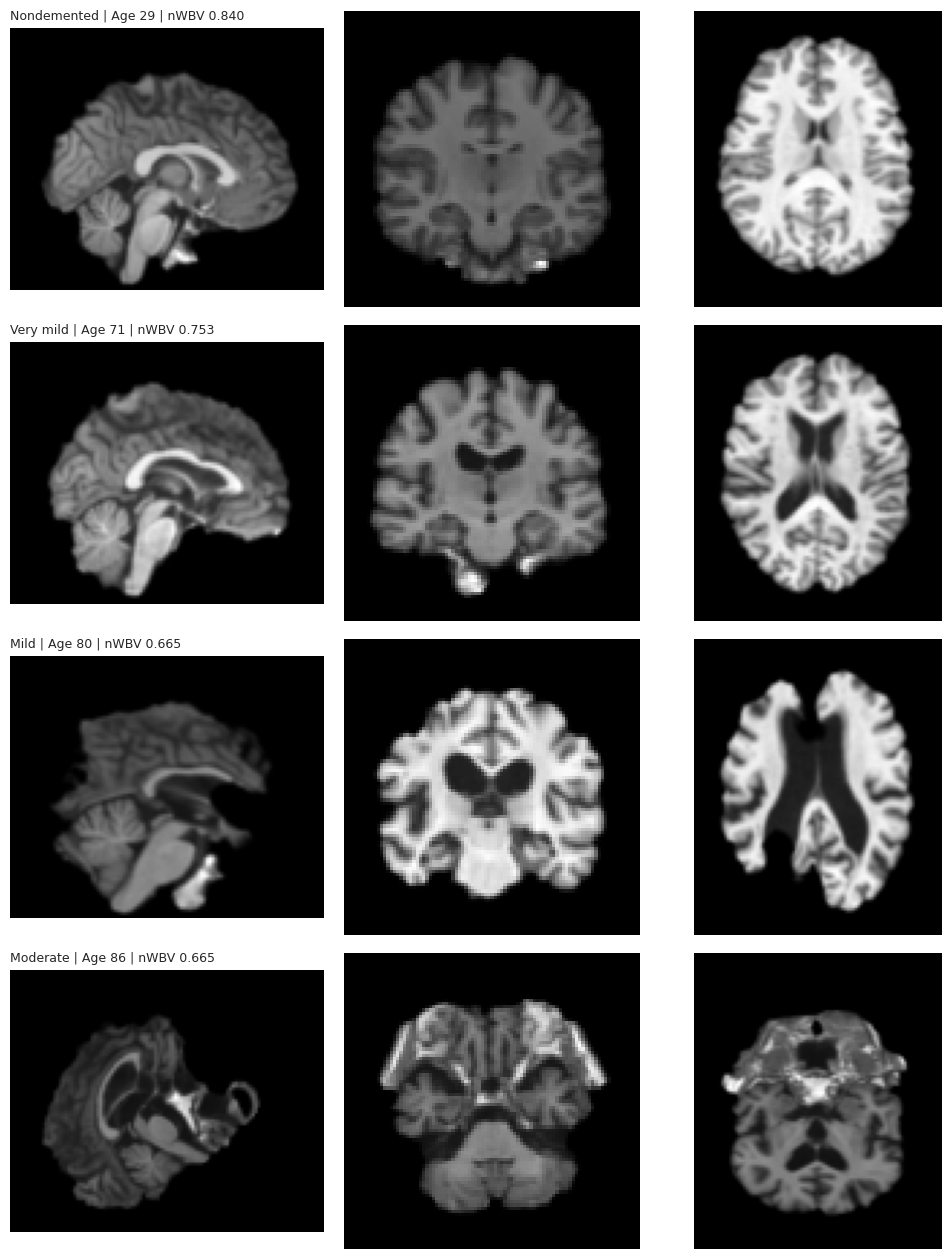

In [28]:
# One example per CDR class
fig, axes = plt.subplots(len(order), 3, figsize=(10, 3.2 * len(order)))
for i, lab in enumerate(order):
    sub = data[data["label_4class"] == lab]
    if sub.empty:
        continue
    r = sub.sample(1, random_state=RANDOM_STATE).iloc[0]
    v = load_vol(r["path"])
    x, y, z = [s // 2 for s in v.shape[:3]]
    for j, sl in enumerate([v[x], v[:, y], v[:, :, z]]):
        axes[i, j].imshow(np.rot90(sl), cmap="gray"); axes[i, j].axis("off")
    axes[i, 0].set_title(f"{lab} | Age {r['Age']:.0f} | nWBV {r['nWBV']:.3f}", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

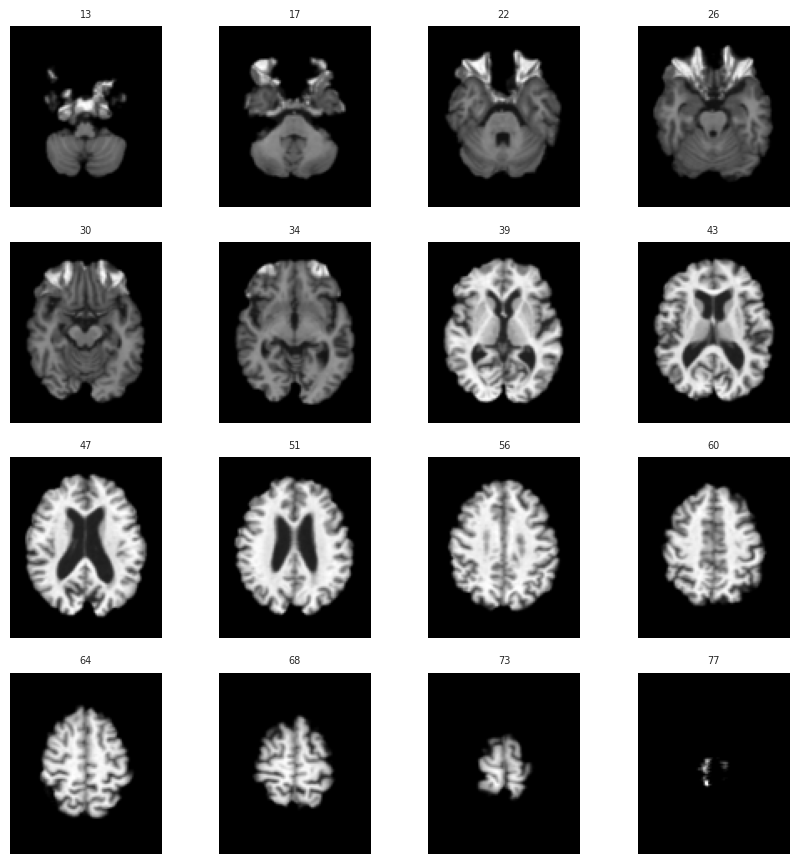

In [29]:
# Axial montage across slices
def montage(vol, n=16, axis=2):
    idx = np.linspace(vol.shape[axis] * 0.15, vol.shape[axis] * 0.85, n).astype(int)
    cols = int(np.sqrt(n))
    fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(2.2 * cols, 2.2 * np.ceil(n / cols)))
    for a, i in zip(axes.ravel(), idx):
        a.imshow(np.rot90(np.take(vol, i, axis=axis)), cmap="gray"); a.axis("off"); a.set_title(i, fontsize=7)
    plt.tight_layout(); plt.show()
montage(vol)

### Labelled sample grid and class similarity

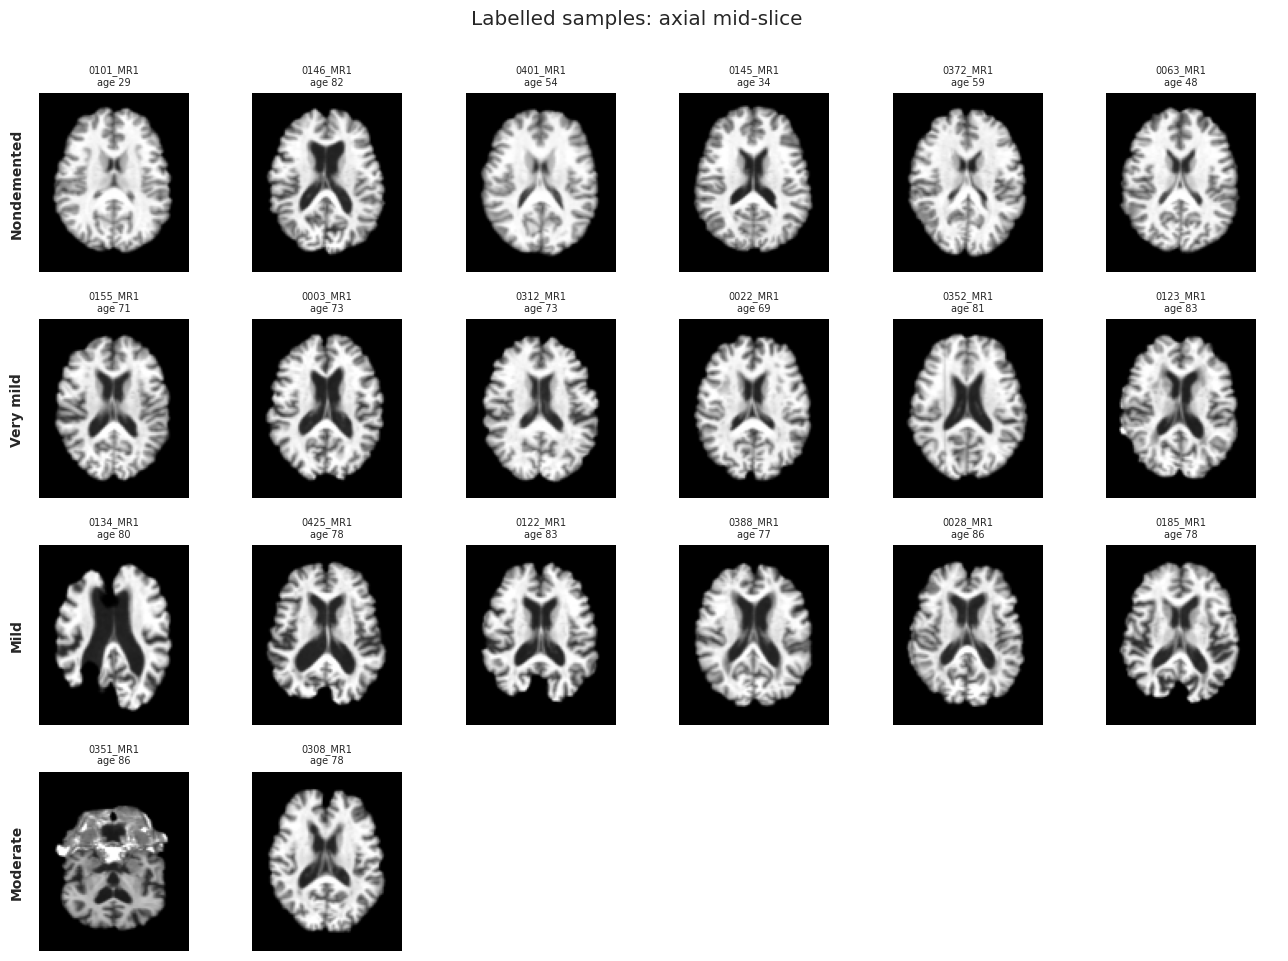

In [30]:
K = 6
classes = [c for c in order if c in counts.index]
fig, axes = plt.subplots(len(classes), K, figsize=(2.2 * K, 2.4 * len(classes)), squeeze=False)
for i, lab in enumerate(classes):
    picks = data[data["label_4class"] == lab].sample(min(K, counts[lab]), random_state=RANDOM_STATE)
    for j in range(K):
        ax = axes[i, j]; ax.axis("off")
        if j < len(picks):
            r = picks.iloc[j]
            ax.imshow(np.rot90(norm01(mid_slice(load_vol(r["path"])))), cmap="gray")
            ax.set_title(f"{r['ID'][-8:]}\nage {r['Age']:.0f}", fontsize=7)
    axes[i, 0].text(-0.1, 0.5, lab, transform=axes[i, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=10, weight="bold")
plt.suptitle("Labelled samples: axial mid-slice", y=1.0); plt.tight_layout(); plt.show()

In [31]:
# Class similarity: correlate each class's mean slice AFTER removing the grand mean
# (otherwise every brain looks ~identical to every other brain)
SZ, PER = 64, 25
vecs = {}
for lab in classes:
    sl = []
    for p in data[data["label_4class"] == lab].sample(min(PER, counts[lab]), random_state=RANDOM_STATE)["path"]:
        s = norm01(mid_slice(load_vol(p)))
        sl.append(zoom(s, (SZ / s.shape[0], SZ / s.shape[1]), order=1))
    vecs[lab] = np.mean(sl, axis=0).ravel()
Mx = pd.DataFrame(vecs)
resid = Mx.sub(Mx.mean(axis=1), axis=0)
sim = resid.corr()

fig = px.imshow(sim.round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Class similarity (correlation of mean slice minus grand mean)")
fig.show()
if len(classes) > 1:
    pairs = sim.where(np.triu(np.ones(sim.shape), 1).astype(bool)).stack().sort_values(ascending=False)
    print("Most similar pair:", pairs.index[0], round(pairs.iloc[0], 2))
    print("Most distinct pair:", pairs.index[-1], round(pairs.iloc[-1], 2))

Most similar pair: ('Very mild', 'Mild') 0.4
Most distinct pair: ('Very mild', 'Moderate') -0.82


## 16. Per-scan feature extraction (pixel stats + quality metrics)

One pass over a random subset of labelled scans; later cells read the `feats` table.

In [32]:
labelled_data = data.dropna(subset=["label_4class"])
N_FEAT = min(150, len(labelled_data))       # set to len(labelled_data) for a full pass
HB = np.linspace(0, 1.5, 76)                # shared histogram bins
rows, hists = [], {}
for _, r in tqdm(labelled_data.sample(N_FEAT, random_state=RANDOM_STATE).iterrows(), total=N_FEAT):
    v = load_vol(r["path"]); fin = np.isfinite(v)
    p99 = np.percentile(v[fin], 99)
    thr = 0.1 * p99
    mask = (v > thr) & fin
    bg = v[(~mask) & fin]
    br = v[mask]
    sl = mid_slice(v); sm = sl > thr
    lap = ndimage.laplace(sl.astype(np.float32))[sm].var() / (sl[sm].mean() ** 2 + 1e-8) if sm.any() else np.nan
    p5, p95 = np.percentile(br, [5, 95])
    rows.append({
        "ID": r["ID"], "label": r["label_4class"], "path": r["path"],
        "channels": 1 if v.ndim == 3 else v.shape[-1],
        "nan_vox": int((~fin).sum()), "min": v.min(), "max": v.max(), "p99": p99,
        "brain_frac": mask.mean(), "mean_brain": br.mean(), "std_brain": br.std(),
        "contrast": (p95 - p5) / (p95 + p5 + 1e-8),
        "snr": br.mean() / bg.std() if bg.size > 10 and bg.std() > 0 else np.nan,
        "sharpness": lap,
        "saturation": (v >= 0.999 * v.max()).mean(),
    })
    hists[r["ID"]] = np.histogram(np.clip(br / p99, 0, 1.5), bins=HB, density=True)[0]
feats = pd.DataFrame(rows)
display(feats.drop(columns=["path"]).describe().T)

  0%|          | 0/150 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
channels,150.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000
nan_vox,150.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
min,150.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
max,150.0,2.225356,2.867917e-01,1.181449,2.037139,2.218912,2.419096,2.861626
p99,150.0,1.083060,4.634840e-02,1.051641,1.066883,1.077217,1.086793,1.544260
brain_frac,150.0,0.264301,9.283853e-03,0.214213,0.259378,0.266112,0.269210,0.292429
mean_brain,150.0,0.704651,1.233138e-02,0.668445,0.697857,0.704484,0.710218,0.761490
std_brain,150.0,0.261225,1.960291e-02,0.233257,0.247517,0.255328,0.271388,0.354611
contrast,150.0,0.643053,3.974590e-02,0.576376,0.612686,0.633362,0.673007,0.746923
snr,150.0,87.691757,4.506061e+00,53.139133,85.872561,87.931450,90.161283,104.242409


### Pixel / colour analysis

In [33]:
print("Channels per image:", feats["channels"].value_counts().to_dict(), "(1 = greyscale, as expected for MRI)")
print("NaN/Inf voxels total:", feats["nan_vox"].sum())
print("Raw intensity max varies by scan:", feats["max"].min(), "to", feats["max"].max())

centers = (HB[:-1] + HB[1:]) / 2
fig = go.Figure()
for lab in classes:
    ids = feats.loc[feats.label == lab, "ID"]
    if ids.empty: continue
    H = np.vstack([hists[i] for i in ids]); mu, sd = H.mean(0), H.std(0)
    fig.add_trace(go.Scatter(x=centers, y=mu, name=lab, mode="lines"))
    fig.add_trace(go.Scatter(x=np.r_[centers, centers[::-1]], y=np.r_[mu + sd, (mu - sd)[::-1]],
                             fill="toself", opacity=.15, line=dict(width=0), showlegend=False, hoverinfo="skip"))
fig.update_layout(title="Normalised brain-voxel intensity density by class (each scan / its p99)",
                  xaxis_title="intensity / p99", yaxis_title="density")
fig.show()

fig = make_subplots(rows=1, cols=3, subplot_titles=["Mean brain intensity", "Brain std", "Raw max"])
for k, c in enumerate(["mean_brain", "std_brain", "max"], 1):
    for lab in classes:
        fig.add_trace(go.Box(y=feats.loc[feats.label == lab, c], name=lab, showlegend=(k == 1),
                             marker_color=px.colors.qualitative.Plotly[classes.index(lab)]), row=1, col=k)
fig.update_layout(height=420, title="Pixel statistics by class"); fig.show()

Channels per image: {1: 150} (1 = greyscale, as expected for MRI)
NaN/Inf voxels total: 0
Raw intensity max varies by scan: 1.1814489364624023 to 2.861626386642456


Wide spread in raw max / mean intensity ⇒ apply **per-volume normalisation** (z-score on brain voxels or percentile clipping) before training.

### Image quality

Flagged scans (any robust-z > 3.5): 10 / 150


,sharpness,snr,contrast,brain_frac,saturation
label,,,,,
Mild,0.080,83.764000,0.698,0.262,0.0
Moderate,0.128,84.206001,0.705,0.237,0.0
Nondemented,0.052,87.939003,0.630,0.266,0.0
Very mild,0.074,88.299004,0.682,0.257,0.0


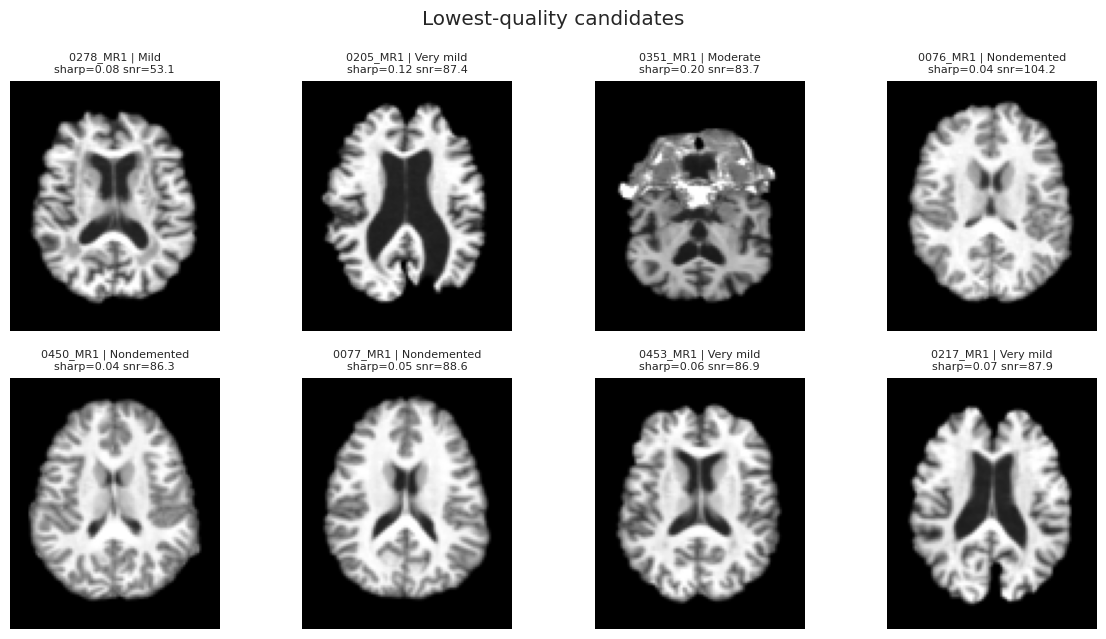

In [34]:
metrics = ["sharpness", "snr", "contrast", "brain_frac", "saturation"]
Z = feats[metrics].apply(robust_z)
feats["n_flags"] = (Z.abs() > 3.5).sum(axis=1)
feats["quality_flag"] = feats["n_flags"] >= 1
print(f"Flagged scans (any robust-z > 3.5): {feats.quality_flag.sum()} / {len(feats)}")
display(feats.groupby("label")[metrics].mean().round(3))

fig = px.scatter_matrix(feats, dimensions=metrics, color="label", hover_name="ID",
                        symbol="quality_flag", height=750, title="Quality metrics (hover for ID)")
fig.update_traces(diagonal_visible=False, marker=dict(size=4)); fig.show()

worst = feats.sort_values(["n_flags", "sharpness"], ascending=[False, True]).head(8)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(np.rot90(norm01(mid_slice(load_vol(r["path"])))), cmap="gray"); ax.axis("off")
    ax.set_title(f"{r['ID'][-8:]} | {r['label']}\nsharp={r['sharpness']:.2f} snr={r['snr']:.1f}", fontsize=8)
plt.suptitle("Lowest-quality candidates"); plt.tight_layout(); plt.show()

## 17. Interactive plots

In [35]:
# (a) Clinical scatter with hover
fig = px.scatter(labeled, x="Age", y="nWBV", color="label_4class", hover_data=["ID", "MMSE", "eTIV", "M/F"],
                 category_orders={"label_4class": order}, title="Age vs nWBV")
fig.show()

# (b) 3D relationship
fig = px.scatter_3d(labeled.dropna(subset=["MMSE"]), x="Age", y="nWBV", z="MMSE", color="label_4class",
                    hover_name="ID", opacity=.8, title="Age / nWBV / MMSE")
fig.show()

# (c) Distribution explorer
fig = px.violin(labeled, x="label_4class", y="nWBV", color="M/F", box=True, points="all",
                category_orders={"label_4class": order}, hover_data=["ID", "Age"], title="nWBV by CDR and sex")
fig.show()

In [36]:
# (d) Slice scroller for one scan (drag the slider)
sub_id = data["ID"].iloc[0]
vol_s = load_vol(data.loc[data.ID == sub_id, "path"].iloc[0])
stack = np.moveaxis(norm01(vol_s), 2, 0)[::2]          # axial slices, every 2nd
fig = px.imshow(stack, animation_frame=0, binary_string=True, origin="lower", title=f"{sub_id}: axial scroll")
fig.show()

In [37]:
# (e) Pick any scan + plane + depth
dd = W.Dropdown(options=list(data["ID"]), description="Scan")
pl = W.ToggleButtons(options=["Sagittal", "Coronal", "Axial"], index=2)
sl_w = W.IntSlider(min=0, max=100, value=50, description="% depth")
out = W.Output()

def draw(*_):
    with out:
        out.clear_output(wait=True)
        v = load_vol(data.loc[data.ID == dd.value, "path"].iloc[0]); n = pl.index
        i = min(int(v.shape[n] * sl_w.value / 100), v.shape[n] - 1)
        r = data.loc[data.ID == dd.value].iloc[0]
        plt.figure(figsize=(4.5, 4.5)); plt.imshow(np.rot90(np.take(v, i, axis=n)), cmap="gray"); plt.axis("off")
        plt.title(f"{dd.value} | CDR {r['CDR']} | Age {r['Age']:.0f}"); plt.show()

for w in (dd, pl, sl_w): w.observe(draw, names="value")
ipd(W.VBox([dd, pl, sl_w, out])); draw()

## 18. Group-mean image per CDR class

Reference shape: (91, 109, 91)
Nondemented n = 15
Very mild n = 15
Mild n = 15
Moderate n = 2


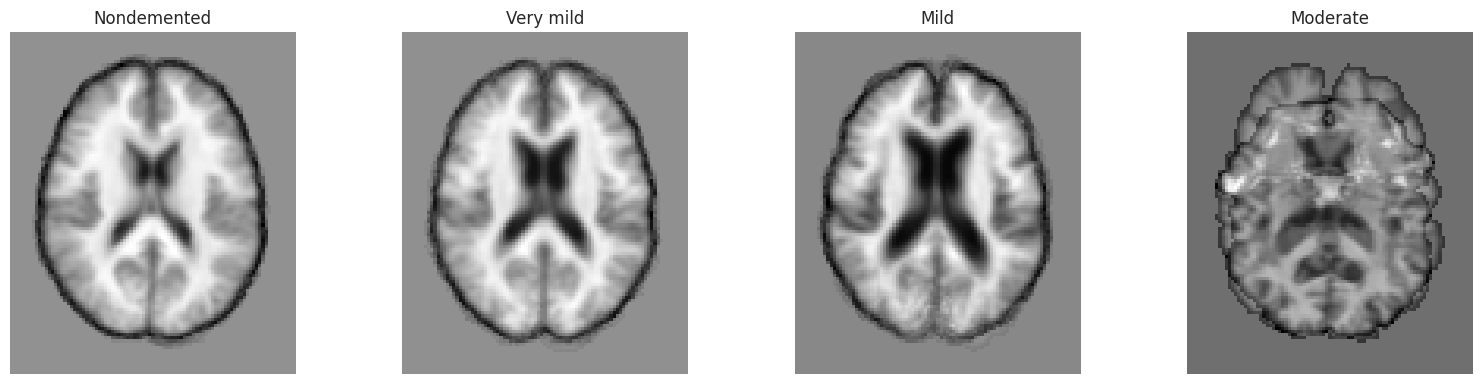

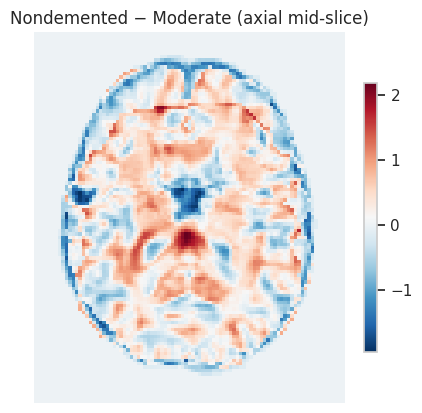

In [38]:
# Only meaningful if volumes share a common space (e.g. atlas-registered T88 images)
ref_shape = tuple(meta["shape"].mode().iloc[0])[:3] if "meta" in globals() else None
print("Reference shape:", ref_shape)

def zscore(v):
    nz = v > 0
    out = np.zeros_like(v)
    out[nz] = (v[nz] - v[nz].mean()) / (v[nz].std() + 1e-8)
    return out

N_PER_GROUP = 15
means = {}
for lab in order:
    sub = data[data["label_4class"] == lab]
    if sub.empty: continue
    acc, n = None, 0
    for p in sub.sample(min(N_PER_GROUP, len(sub)), random_state=RANDOM_STATE)["path"]:
        v = load_vol(p)
        if v.shape[:3] != ref_shape: continue
        v = zscore(v[..., 0] if v.ndim > 3 else v)
        acc = v if acc is None else acc + v
        n += 1
    if n: means[lab] = acc / n; print(lab, "n =", n)

fig, axes = plt.subplots(1, len(means), figsize=(4 * len(means), 4))
axes = np.atleast_1d(axes)
for ax, (lab, m) in zip(axes, means.items()):
    ax.imshow(np.rot90(m[:, :, m.shape[2] // 2]), cmap="gray"); ax.set_title(lab); ax.axis("off")
plt.tight_layout(); plt.show()

# Difference: Nondemented vs most severe available
if "Nondemented" in means and len(means) > 1:
    other = [k for k in order[::-1] if k in means and k != "Nondemented"][0]
    d = means["Nondemented"] - means[other]
    plt.figure(figsize=(5, 5)); plt.imshow(np.rot90(d[:, :, d.shape[2] // 2]), cmap="RdBu_r"); plt.colorbar(shrink=.7)
    plt.title(f"Nondemented − {other} (axial mid-slice)"); plt.axis("off"); plt.show()

## 19. Modelling-readiness checks

In [39]:
# 1) Leakage risk: same subject in multiple sessions must stay in ONE split
multi = data.groupby("subject").size()
print("Subjects with >1 session in usable data:", (multi > 1).sum())

# 2) Age confound between classes
print(labeled.groupby("label_4class")["Age"].agg(["count", "mean", "std", "min", "max"]).reindex(order).dropna(how="all"))

# 3) Subject-level stratified split example
from sklearn.model_selection import StratifiedGroupKFold
lab_df = data.dropna(subset=["label_binary"]).reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for k, (tr, te) in enumerate(sgkf.split(lab_df, lab_df["label_binary"], groups=lab_df["subject"])):
    print(f"fold {k}: train={len(tr)}, test={len(te)}, test %demented={(lab_df.loc[te,'label_binary']=='Demented').mean():.2f}")

Subjects with >1 session in usable data: 20
              count       mean        std  min  max
label_4class                                       
Nondemented     336  43.797619  23.754103   18   94
Very mild        70  76.214286   7.186729   62   92
Mild             28  77.750000   6.990072   65   96
Moderate          2  82.000000   5.656854   78   86
fold 0: train=348, test=88, test %demented=0.26
fold 1: train=350, test=86, test %demented=0.34
fold 2: train=351, test=85, test %demented=0.18
fold 3: train=348, test=88, test %demented=0.20
fold 4: train=347, test=89, test %demented=0.17


## 20. Summary checklist
# Total sessions / subjects / usable image+CSV pairs:
436 sessions, 416 subjects, 436 usable pairs. There are 436 NIfTI files with one per session, and no CSV rows without an image or images without a CSV row. 20 subjects have a second scan (MR2), and all 20 are CDR 0.

# Class balance (CDR 0 / 0.5 / 1 / 2):
336 / 70 / 28 / 2 sessions (77.1% / 16.1% / 6.4% / 0.5%). The majority-to-minority ratio is 168 : 1, which is severe imbalance. CDR 2 has only 2 scans, so it can’t be learned or evaluated, and I’d merge it into CDR ≥ 1 (30 scans). The binary task (336 nondemented vs 100 demented) is 3.4 : 1, which is manageable with class weights. Among age ≥ 60 only, it’s 98 / 70 / 28 / 2, so demented vs nondemented is roughly balanced at 100 vs 98.

# Structural missingness (age < 60):
MMSE and Educ are missing for 201 of 238 subjects under 60 and for 0 of 198 aged 60+. SES is missing for 202 of 238 under 60 and 18 of 198 aged 60+. This missingness is structural, not random, so don’t impute it. CDR is never missing in this CSV, and all 238 subjects under 60 are CDR 0 even though they have no MMSE. From the data alone, that looks like a CDR 0 default rather than a clinical assessment, so treat those labels with caution. My earlier note that CDR would be blank for young subjects was wrong for this file.  

# Image variant, shape, voxel size, orientation uniform? 
Yes, fully uniform:
Variant: *_mpr_n4_anon_sbj_111_normalised.nii for 434 files. 2 files use an fdcanon…dfp_normalised name, but they have the same shape and spacing.
Shape: (91, 109, 91), 436 of 436.
Voxel size: 2 × 2 × 2 mm, a 182 × 218 × 182 mm field of view.
Orientation and type: LAS, float32.
Resampling: none needed.

# Intensity normalisation needed?
Light normalisation only. The scans are already scaled: per-scan p99 is about 1.08 ± 0.05 and mean brain intensity is 0.705 ± 0.012. The raw max still varies from 1.18 to 2.86 because of a few bright voxels, so don’t normalise by max. Clip at about the 99.5th percentile, or z-score over non-zero brain voxels. This is based on a 150-scan sample. About 10 of 150 scans were flagged on quality metrics, which is worth a visual check.

# Split strategy: subject-level, stratified by label
Use StratifiedGroupKFold with groups=subject, so the 20 repeat scans never straddle train and test. In your run the test-fold demented share ranged from 17% to 34% against about 23% overall. That uneven spread is a sign of how little data there is, so use repeated seeds and report variance. For the binary task, class weights are about 0.65 for nondemented and 2.2 for demented (computed from 336 vs 100).

# Confounds noted (age, sex, eTIV): 
Age: this is the biggest one. Nondemented subjects average 43.8 years (range 18–94), while very mild, mild and moderate average 76–82. Every under-60 subject is CDR 0, so a model can score well by detecting a young brain. Within age ≥ 60, age does not differ by CDR (Kruskal-Wallis p = 0.53), and nWBV still separates the groups (p ≈ 1e-7). That makes the 60+ subset (198 subjects) the cleaner test. Age and nWBV are strongly correlated (Spearman ρ = −0.87).
Sex: across all subjects there’s no association with dementia (p = 0.65), but that hides an effect. Among those aged 60+, 61% of males (41 of 67) are demented vs 45% of females (59 of 131), chi-square p ≈ 0.03.
eTIV: it doesn’t differ by CDR (p = 0.98 overall, 0.28 among 60+), but it’s a strong sex proxy (males 1592 vs females 1413 mm³, p ≈ 1e-31). ASF is almost exactly the inverse of eTIV (ρ = −0.99), so use only one of them.
Imaging: mean-slice sharpness is higher in the Mild and Moderate groups. That more likely reflects atrophy than a scanner artifact, but I haven’t verified it.